# Behaviours and baking

Python motion packaged as behaviours, then baked into SMIL so the scene plays in a browser just like
the video.

    python 16_behaviors.py              writes 16_workshop.svg (animated) and 16_workshop.pptx

In [1]:
import svgwriter as svg
from svgwriter.motion.video.behaviors import wiggle

A behaviour is a function of the element and the time. `@svg.preset.behavior` checks its shape and
registers it, so `element.animate.turn()` finds it by name. It starts from `element.home`, the element
as it was when the behaviour was attached, so each frame is computed afresh and never drifts.

In [2]:
INK = "#1f2937"
PAPER = "#f8fafc"
STEEL = "#64748b"
BRASS = "#d97706"


@svg.preset.behavior
def turn(element: svg.Element, seconds: float, *, speed: float = 90.0) -> None:
    """Turn about the anchor at *speed* degrees per second."""
    element.t = element.home.t
    element.rotate(speed * seconds)

The scene attaches behaviours in `build`: by name, or typed with `self.attach`, which checks the
options against the function. `update` still runs every frame, after the behaviours.

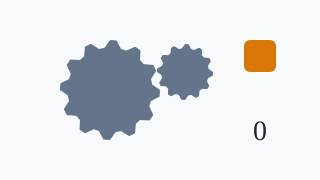

In [3]:
class Workshop(svg.Scene):
    width, height, fps, duration = 320, 180, 24, 2.0

    def build(self, doc: svg.Document) -> None:
        doc.rect(0, 0, self.width, self.height, fill=PAPER)
        big = doc.add(svg.preset.shape.get("gear")(110, 90, 50, fill=STEEL))
        big.animate.turn(speed=90)
        small = doc.add(svg.preset.shape.get("gear")(185, 72, 28, fill=STEEL))
        small.animate.turn(speed=-160)
        self.sign = self.attach(doc.rect(244, 40, 32, 32, rx=6, fill=BRASS), wiggle, angle=12, period=0.4)
        self.counter = doc.text("0", x=260, y=140, font_size=28, fill=INK, text_anchor="middle")

    def update(self, seconds: float) -> None:
        self.counter.children[0] = str(int(seconds * 4))


workshop = Workshop()
workshop.render(0.5)
workshop

`bake()` samples the scene and writes the motion as SMIL: the gears become one rotation each, the
sign a few keyframes, and the counter one text per value shown in turn. Saving the scene as `.svg` or
`.pptx` bakes it the same way.

['animateTransform', 'set']


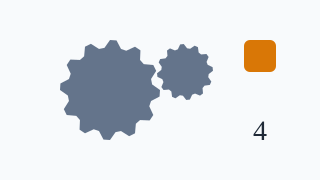

In [4]:
baked = workshop.bake()
print(sorted({child.tag for element in baked.root.iter() for child in element.children
              if isinstance(child, svg.Element) and child.category.name == "ANIMATION"}))
baked.at(1.0)

In [5]:
if __name__ == "__main__":
    workshop.save("16_workshop.svg")
    workshop.save("16_workshop.pptx")